# Importing Libraries

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
import os

# Test set Image Processing

In [2]:
valid_dir = "data/valid"

validation_set = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=(128, 128),
    shuffle=True
)
class_names = validation_set.class_names
print("Classes:", class_names)

Found 17572 files belonging to 38 classes.
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider

# Loading Model

In [3]:
model = tf.keras.models.load_model("trained_plant_disease_model.keras")

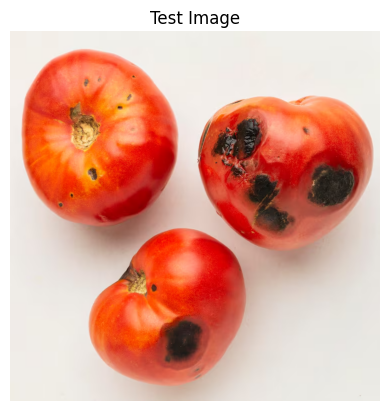

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
Raw predictions: [[8.1337723e-20 5.2439992e-17 3.7264836e-13 2.4451950e-19 2.7785415e-24
  3.5241195e-18 2.3615395e-23 5.5893915e-16 4.1125518e-22 1.6766519e-17
  1.8484672e-23 5.4519753e-19 6.6034912e-14 6.0158887e-13 3.0200072e-22
  1.5680334e-21 2.3016741e-16 3.5748347e-21 4.4449713e-19 4.0240196e-21
  9.8832877e-20 1.4249129e-15 1.7970946e-13 2.6406519e-18 1.0726314e-21
  3.4232185e-19 1.0000000e+00 2.4495336e-21 1.5134161e-19 6.9541805e-14
  7.4548291e-14 5.0990214e-20 8.1549420e-17 4.6929658e-18 3.0378301e-18
  6.3754155e-19 4.1877998e-21 4.3015742e-14]]
Predicted class index: 26
Predicted label: Strawberry___Leaf_scorch


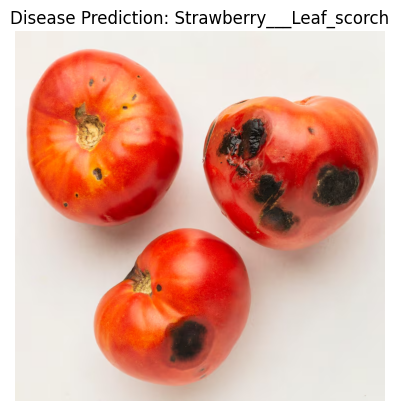

In [4]:
image_path = "data/test/moldy-tomatoes-leftover-food-waste_23-2148764835.jpg"

# Load image
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display input image
plt.imshow(img)
plt.title("Test Image")
plt.axis("off")
plt.show()

# Preprocess
image = tf.keras.preprocessing.image.load_img(image_path, target_size=(128, 128))
input_arr = tf.keras.preprocessing.image.img_to_array(image)
input_arr = np.expand_dims(input_arr, axis=0)  # make it batch-like

# Prediction
predictions = model.predict(input_arr)
result_index = np.argmax(predictions)

print("Raw predictions:", predictions)
print("Predicted class index:", result_index)
print("Predicted label:", class_names[result_index])

# Display with prediction
plt.imshow(img)
plt.title(f"Disease Prediction: {class_names[result_index]}")
plt.axis("off")
plt.show()